In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Consolidado_ambiental_nodos_Comuna_22_AD.xlsx to Consolidado_ambiental_nodos_Comuna_22_AD.xlsx


In [ ]:
import pandas as pd


ruta_archivo = '/content/Consolidado_ambiental_nodos_Comuna_22_AD.xlsx'

df = pd.read_excel(ruta_archivo, sheet_name="Datos semanales")
dic = pd.read_excel(ruta_archivo, sheet_name="Diccionario")

In [ ]:
import numpy as np


In [ ]:
print(df.shape) # fase de conocimiento de los datos
print(df.dtypes.value_counts()) # cuantos tipos de variables hay y cuantos hay de cada una
print(df.groupby("nodo").size())# agrupar los datos por nodo para su mejor procesamiento
print(sorted(set(range(1, 19)) - set(df["nodo"])))# cuales nodos faltan
print(df["inicio_semana"].min(), df["inicio_semana"].max())# que periodo cubre el estudio cual es el rango

(2873, 49)
float64           38
int64              9
datetime64[ns]     2
Name: count, dtype: int64
nodo
1     169
2     169
3     169
4     169
5     169
6     169
7     169
8     169
10    169
11    169
12    169
13    169
14    169
15    169
16    169
17    169
18    169
dtype: int64
[9]
2023-06-26 00:00:00 2026-09-14 00:00:00


In [ ]:
print("Filas duplicadas:", df.duplicated().sum())# cuantos datos duplicados hay
print("Duplicados nodo+semana:", df.duplicated(["nodo", "inicio_semana"]).sum()) #cuenta repeticiones del mismo nodo en la misma semana; cada combinación debe ser única

iso = df["inicio_semana"].dt.isocalendar() # calcula año y semana ISO a partir de la fecha; sirve para verificar las columnas año y semana
print("No lunes:", (df["inicio_semana"].dt.dayofweek != 0).sum()) # cuenta fechas de inicio que no son lunes (lunes = 0); deben ser 0 según el diccionario
print("fin != inicio+6:", ((df["fin_semana"] - df["inicio_semana"]).dt.days != 6).sum()) # cuenta semanas que no duran 7 días (inicio + 6 = fin); deben ser 0
print("Año/semana ISO inconsistentes:", # cuenta filas donde año o semana no coinciden con la fecha; deben ser 0
      ((iso.year != df["año"]) | (iso.week != df["semana"])).sum())

Filas duplicadas: 0
Duplicados nodo+semana: 0
No lunes: 0
fin != inicio+6: 0
Año/semana ISO inconsistentes: 0


In [ ]:
falt = df.isna().sum().to_frame("n_NA")  # cuenta los vacíos (NA) de cada columna y los pone en una tabla
falt["pct"] = (falt["n_NA"] / len(df) * 100).round(2)  # convierte ese conteo en porcentaje del total de filas; permite comparar columnas
print(falt[falt["n_NA"] > 0])  # muestra solo las columnas que sí tienen faltantes; evita imprimir 49 líneas
print("Filas con algún NA:", df.isna().any(axis=1).sum())  # cuenta filas con al menos un vacío; dice cuántas observaciones están incompletas
print(df.isna().sum(axis=1).groupby(df["nodo"]).sum())  # suma los vacíos por nodo; revela si el problema se concentra en pocos sensores (15 y 16)

                             n_NA   pct
temperatura_media_c             9  0.31
humedad_media_pct               9  0.31
radiacion_media                 9  0.31
uv_media                        9  0.31
viento_medio                    4  0.14
ruido_medio_db                  5  0.17
pm25_media                      5  0.17
pm10_media                      5  0.17
temperatura_min_c               9  0.31
humedad_min_pct                 9  0.31
viento_min                      4  0.14
ruido_min_db                    5  0.17
pm25_min                        5  0.17
pm10_min                        5  0.17
temperatura_max_c               9  0.31
humedad_max_pct                 9  0.31
radiacion_max                   9  0.31
uv_max                          9  0.31
viento_max                      4  0.14
ruido_max_db                    5  0.17
pm25_max                        5  0.17
pm10_max                        5  0.17
amplitud_termica_c              9  0.31
precipitacion_semanal           4  0.14


In [ ]:
grupos = {  # diccionario con los tres valores de cada variable (mínimo, media, máximo)
    "temperatura": ("temperatura_min_c", "temperatura_media_c", "temperatura_max_c"),  # temperatura
    "humedad": ("humedad_min_pct", "humedad_media_pct", "humedad_max_pct"),  # humedad relativa
    "viento": ("viento_min", "viento_medio", "viento_max"),  # velocidad del viento
    "ruido": ("ruido_min_db", "ruido_medio_db", "ruido_max_db"),  # ruido en decibelios
    "pm25": ("pm25_min", "pm25_media", "pm25_max"),  # material particulado fino
    "pm10": ("pm10_min", "pm10_media", "pm10_max"),  # material particulado grueso
}  # cierra el diccionario
for nombre, (mn, md, mx) in grupos.items():  # recorre cada variable con su mínimo, media y máximo
    mal = (df[mn] > df[md]) | (df[md] > df[mx])  # marca las filas donde el mínimo supera a la media o la media supera al máximo (imposible)
    print(nombre, int(mal.sum()))  # imprime cuántas filas incoherentes tiene cada variable
print("PM2.5 media > PM10 media:", (df["pm25_media"] > df["pm10_media"]).sum())  # PM2.5 está contenido en PM10, así que su media no puede ser mayor

temperatura 0
humedad 1
viento 0
ruido 0
pm25 0
pm10 0
PM2.5 media > PM10 media: 3


       temperatura_media_c  humedad_media_pct  radiacion_media  pm25_media  \
count              2864.00            2864.00          2864.00     2868.00   
mean                 25.72              74.85           173.19       11.94   
std                  24.73               7.01            68.49       22.93   
min                  21.39               0.00             0.00        0.00   
25%                  23.73              70.29           145.92        7.45   
50%                  24.63              75.43           170.78       10.17   
75%                  25.56              79.76           191.26       12.69   
max                 615.25              95.80           756.73      505.58   

       ruido_medio_db  huevos_aedes  
count         2868.00       2801.00  
mean            51.27         79.30  
std              7.91        115.95  
min             34.50          0.00  
25%             45.36          0.00  
50%             49.01         47.00  
75%             58.35        11

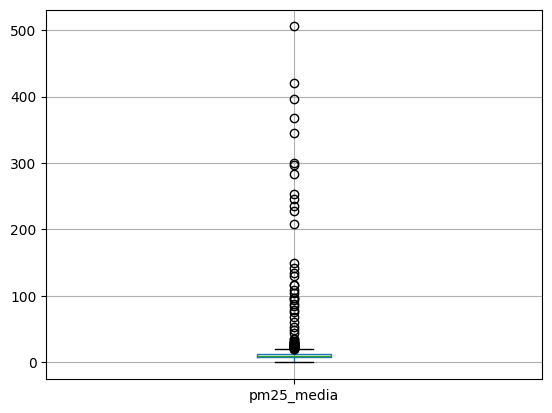

In [ ]:
import matplotlib.pyplot as plt  # librería para hacer gráficos

print(df[["temperatura_media_c", "humedad_media_pct", "radiacion_media", "pm25_media", "ruido_medio_db", "huevos_aedes"]].describe().round(2))  # resumen (promedio, mínimo, máximo) de las variables clave; los máximos absurdos se ven aquí
print("Temperatura > 50:", (df["temperatura_max_c"] > 50).sum())  # cuenta temperaturas imposibles (6)
print("Humedad media = 0:", (df["humedad_media_pct"] == 0).sum())  # cuenta humedades medias de 0 % (5)
print("Radiación media = 0:", (df["radiacion_media"] == 0).sum())  # cuenta radiaciones medias de 0 (2)
print("PM2.5 máximo = 1000:", (df["pm25_max"] == 1000).sum())  # cuenta semanas donde PM2.5 llegó al tope del sensor (114)
df.boxplot(column="pm25_media")  # dibuja un boxplot de PM2.5; los puntos aislados arriba son valores atípicos
plt.show()  # muestra el gráfico en pantalla

In [ ]:
print("Lecturas > 672:", (df["lecturas_surth"] > 672).sum())  # cuenta semanas con más lecturas de las posibles en 7 días (288)
print("Cobertura < 50 %:", (df["cobertura_min_pct"] < 50).sum())  # cuenta semanas con menos de la mitad de las lecturas (131)
print("Cobertura = 0 %:", (df["cobertura_min_pct"] == 0).sum())  # cuenta semanas sin ninguna lectura (3)

Lecturas > 672: 288
Cobertura < 50 %: 131
Cobertura = 0 %: 3


In [ ]:
# 1) Temperatura imposible
fila_mala = df["temperatura_max_c"] > 50  # busca las filas donde la temperatura máxima pasa de 50 °C; en Cali eso es imposible, es error del sensor
df.loc[fila_mala, ["temperatura_media_c", "temperatura_min_c", "temperatura_max_c", "amplitud_termica_c"]] = np.nan  # en esas filas deja vacías las 4 columnas de temperatura; la amplitud también, porque se calcula con la temperatura dañada
df.loc[df["temperatura_2sem_previas_c"] > 50, "temperatura_2sem_previas_c"] = np.nan  # el error también se coló en el promedio de las 2 semanas previas; se borra para que no se propague

# 2) Humedad imposible
df.loc[df["humedad_media_pct"] == 0, "humedad_media_pct"] = np.nan  # una semana no puede tener humedad promedio de 0 %, así que se deja vacía

# 3) Radiación imposible
df.loc[df["radiacion_media"] == 0, "radiacion_media"] = np.nan  # una semana no puede tener radiación promedio de 0, así que se deja vacía

# Guardar
df.to_excel("base_limpia.xlsx", index=False)  # guarda la base limpia en un Excel nuevo; el archivo original no se modifica

# ANALISIS BIVARIADO

###preparación

In [ ]:
df["nodo"] = df["nodo"].astype(str)
orden_nodos = sorted(df["nodo"].unique(), key=int)

In [ ]:
df["mes"] = df["inicio_semana"].dt.month

In [ ]:
df["ovitrampa"] = (
    pd.Series(np.where(df["huevos_aedes"] > 0, "Positiva", "Negativa"), index=df.index)
      .where(df["huevos_aedes"].notna())
)

df["lluvia_2sem"] = pd.qcut(
    df["precipitacion_2sem_previas"], 4,
    labels=["Q1 (menos lluvia)", "Q2", "Q3", "Q4 (más lluvia)"]
)


In [ ]:
# Solo semanas con respuesta registrada (no NaN)
df_aedes = df.dropna(subset=["huevos_aedes"])

In [ ]:
# Filtro de calidad para variables ambientales
UMBRAL_COBERTURA = 50   # % mínimo de lecturas en la semana
df_cal       = df[df["cobertura_min_pct"] >= UMBRAL_COBERTURA]
df_aedes_cal = df_cal.dropna(subset=["huevos_aedes"])
print("Semanas totales                     :", len(df))
print("Semanas con huevos_aedes registrado :", len(df_aedes))
print(f"Semanas con cobertura >= {UMBRAL_COBERTURA}%         :", len(df_cal))
print(f"Semanas con ambos (para 5.4-5.8)    :", len(df_aedes_cal))
print(df_aedes["ovitrampa"].value_counts(normalize=True).mul(100).round(1).to_string())

Semanas totales                     : 2873
Semanas con huevos_aedes registrado : 2801
Semanas con cobertura >= 50%         : 2742
Semanas con ambos (para 5.4-5.8)    : 2676
ovitrampa
Positiva    65.9
Negativa    34.1


## 5. Análisis bivariado: categórica vs numérica

### 5.1 Huevos de *Aedes* promedio por nodo

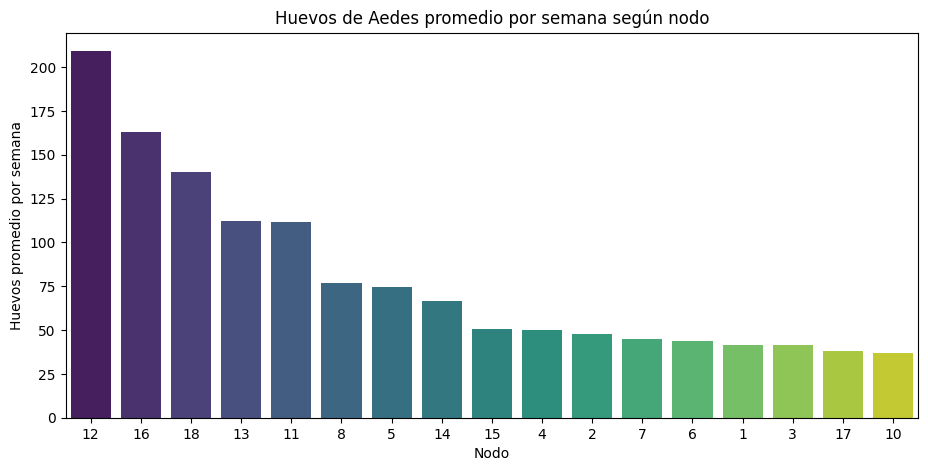

In [ ]:
import seaborn as sns

orden_prom = df.groupby("nodo")["huevos_aedes"].mean().sort_values(ascending=False).index

plt.figure(figsize=(11, 5))
sns.barplot(
    data=df, x="nodo", y="huevos_aedes",
    order=orden_prom, hue="nodo", hue_order=orden_prom,
    estimator="mean", errorbar=None,
    palette="viridis", legend=False
)
plt.title("Huevos de Aedes promedio por semana según nodo")
plt.xlabel("Nodo")
plt.ylabel("Huevos promedio por semana")
plt.show()

### 5.2 Distribución de huevos por nodo (boxplot condicionado)

El barplot da un solo número por nodo; el boxplot muestra la **distribución completa** (mediana, variabilidad y outliers).

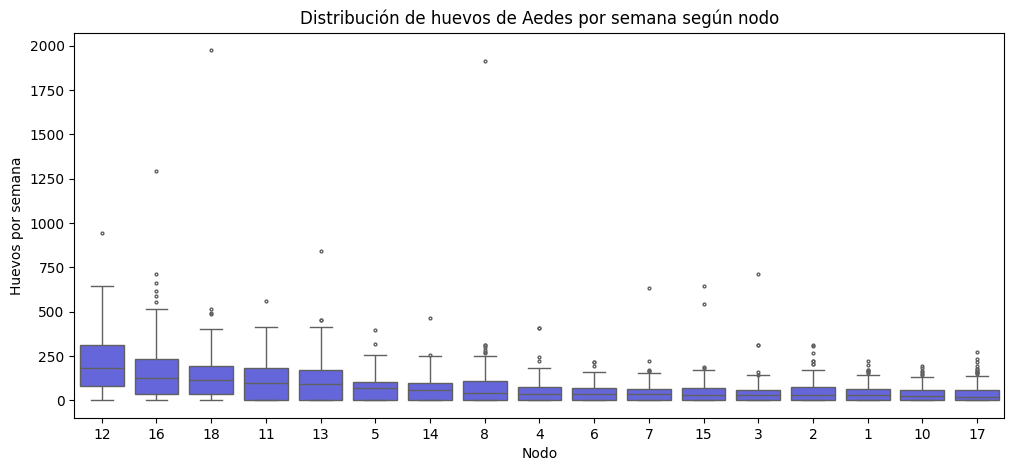

In [ ]:
orden_mediana = df.groupby("nodo")["huevos_aedes"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5))
sns.boxplot(data=df, x="nodo", y="huevos_aedes", order=orden_mediana,
            color="#5353EE", fliersize=2)
plt.title("Distribución de huevos de Aedes por semana según nodo")
plt.xlabel("Nodo")
plt.ylabel("Huevos por semana")
plt.show()

### 5.3 ¿Los nodos difieren en sus condiciones ambientales?

Si hay nodos con más huevos, una pregunta natural es si también tienen un **ambiente distinto**. Primero un violinplot y luego un panorama con varias variables.

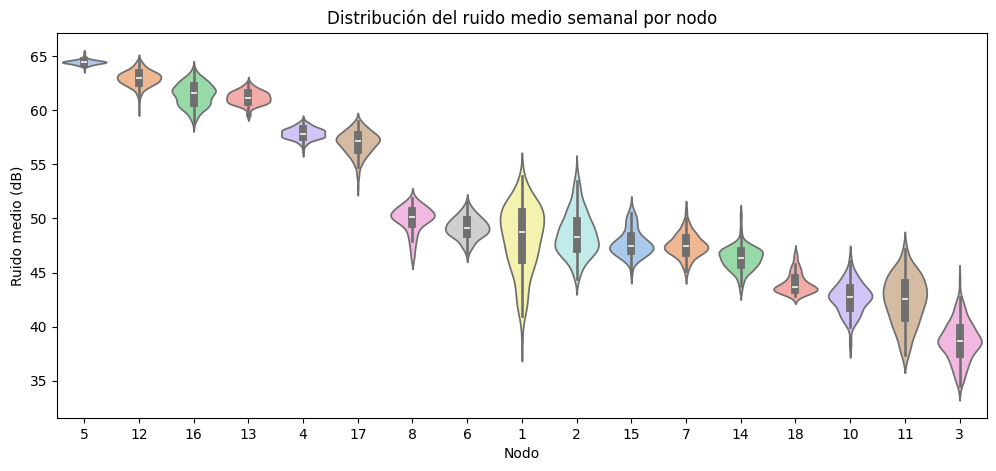

In [ ]:
orden_ruido = df_cal.groupby("nodo")["ruido_medio_db"].median().sort_values(ascending=False).index

plt.figure(figsize=(12, 5))
sns.violinplot(data=df_cal, x="nodo", y="ruido_medio_db", order=orden_ruido,
               palette="pastel", hue="nodo", hue_order=orden_ruido, legend=False)
plt.title("Distribución del ruido medio semanal por nodo")
plt.xlabel("Nodo")
plt.ylabel("Ruido medio (dB)")
plt.show()

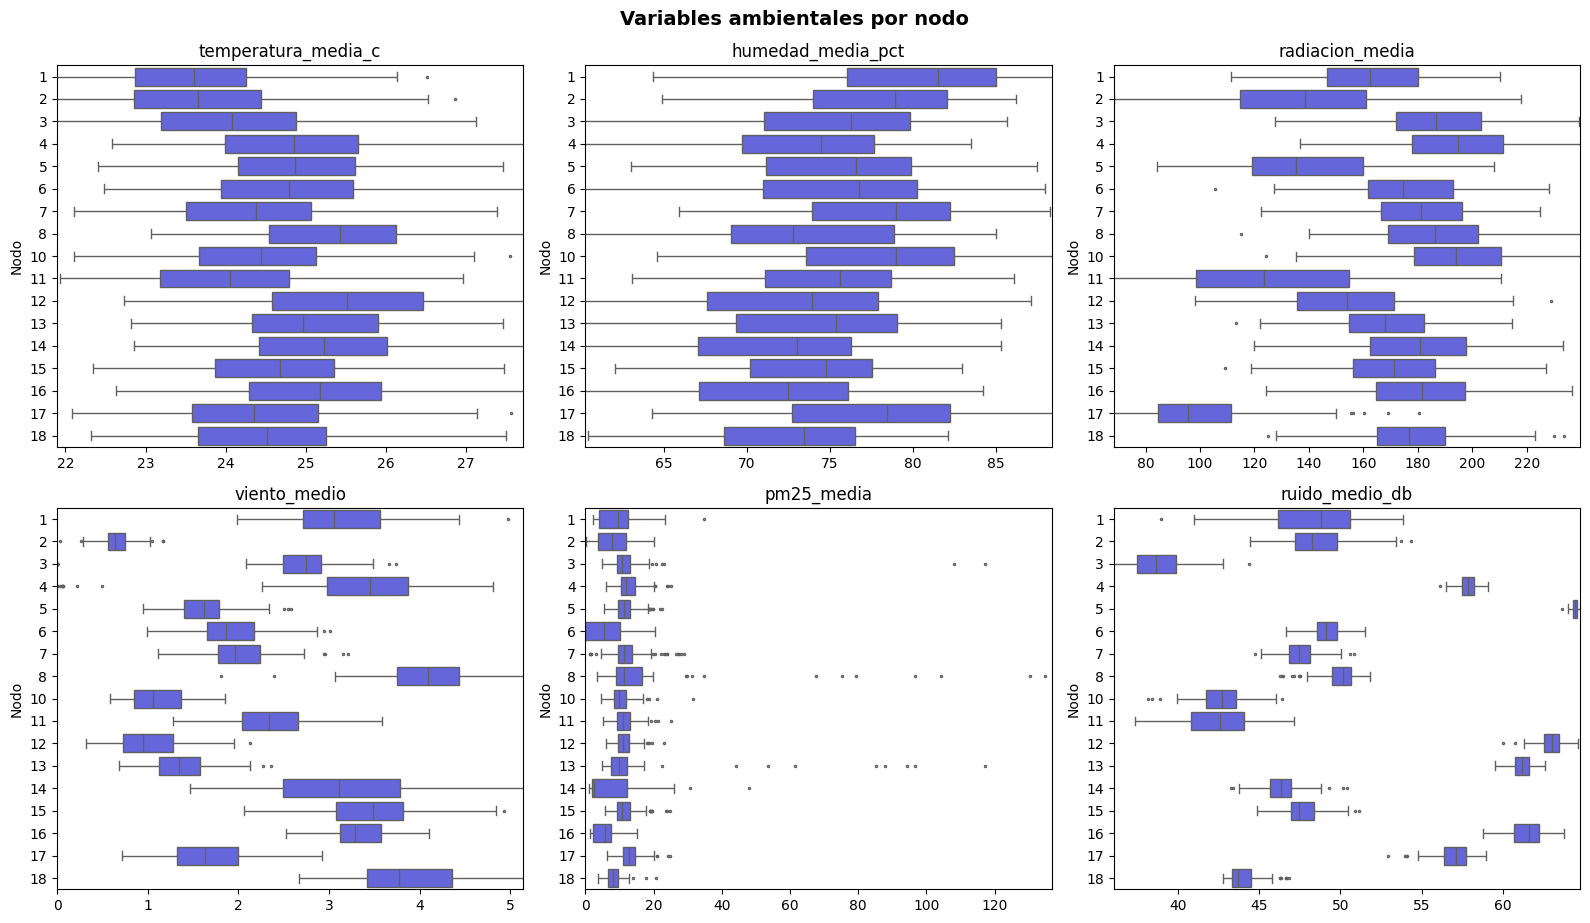

In [ ]:
vars_amb = ["temperatura_media_c", "humedad_media_pct", "radiacion_media",
            "viento_medio", "pm25_media", "ruido_medio_db"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for ax, var in zip(axes, vars_amb):
    sns.boxplot(data=df_cal, y="nodo", x=var, order=orden_nodos, ax=ax,
                color="#5353EE", fliersize=1.5, orient="h")
    # Recortamos el eje al rango p0.5-p99.5 para que unos pocos extremos no aplasten el gráfico
    ax.set_xlim(df_cal[var].quantile(0.005), df_cal[var].quantile(0.995))
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("Nodo")

plt.tight_layout()
plt.suptitle("Variables ambientales por nodo", y=1.02, fontsize=14, fontweight="bold")
plt.show()

### 5.4 ¿Más lluvia reciente implica más huevos?

**Hipótesis:** las semanas que vienen después de periodos lluviosos tienen más huevos


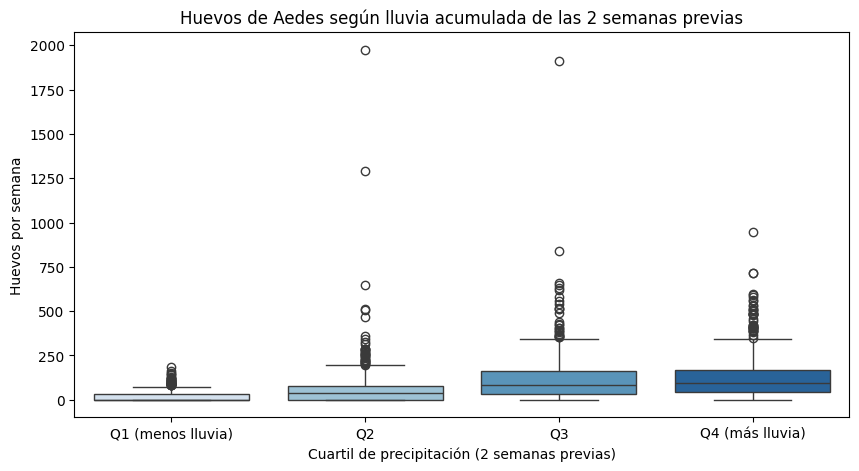

In [ ]:
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df_aedes_cal.dropna(subset=["lluvia_2sem"]),
    x="lluvia_2sem", y="huevos_aedes",
    palette="Blues", hue="lluvia_2sem", legend=False,
)
plt.title("Huevos de Aedes según lluvia acumulada de las 2 semanas previas")
plt.xlabel("Cuartil de precipitación (2 semanas previas)")
plt.ylabel("Huevos por semana")
plt.show()

In [ ]:
# Medianas y promedios por cuartil, para acompañar el gráfico
(df_aedes_cal.groupby("lluvia_2sem")["huevos_aedes"]
         .agg(["count", "median", "mean"]).round(1))

/tmp/ipykernel_1047/378915910.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  (df_aedes_cal.groupby("lluvia_2sem")["huevos_aedes"]


,count,median,mean
lluvia_2sem,,,
Q1 (menos lluvia),623,0.0,18.4
Q2,669,36.0,60.0
Q3,684,82.0,113.0
Q4 (más lluvia),682,93.5,124.9


### 5.5 Ovitrampa positiva vs negativa

Convertimos la respuesta en **binaria** (*huevos_aedes > 0*) y comparamos las variables ambientales entre semanas positivas y negativas.


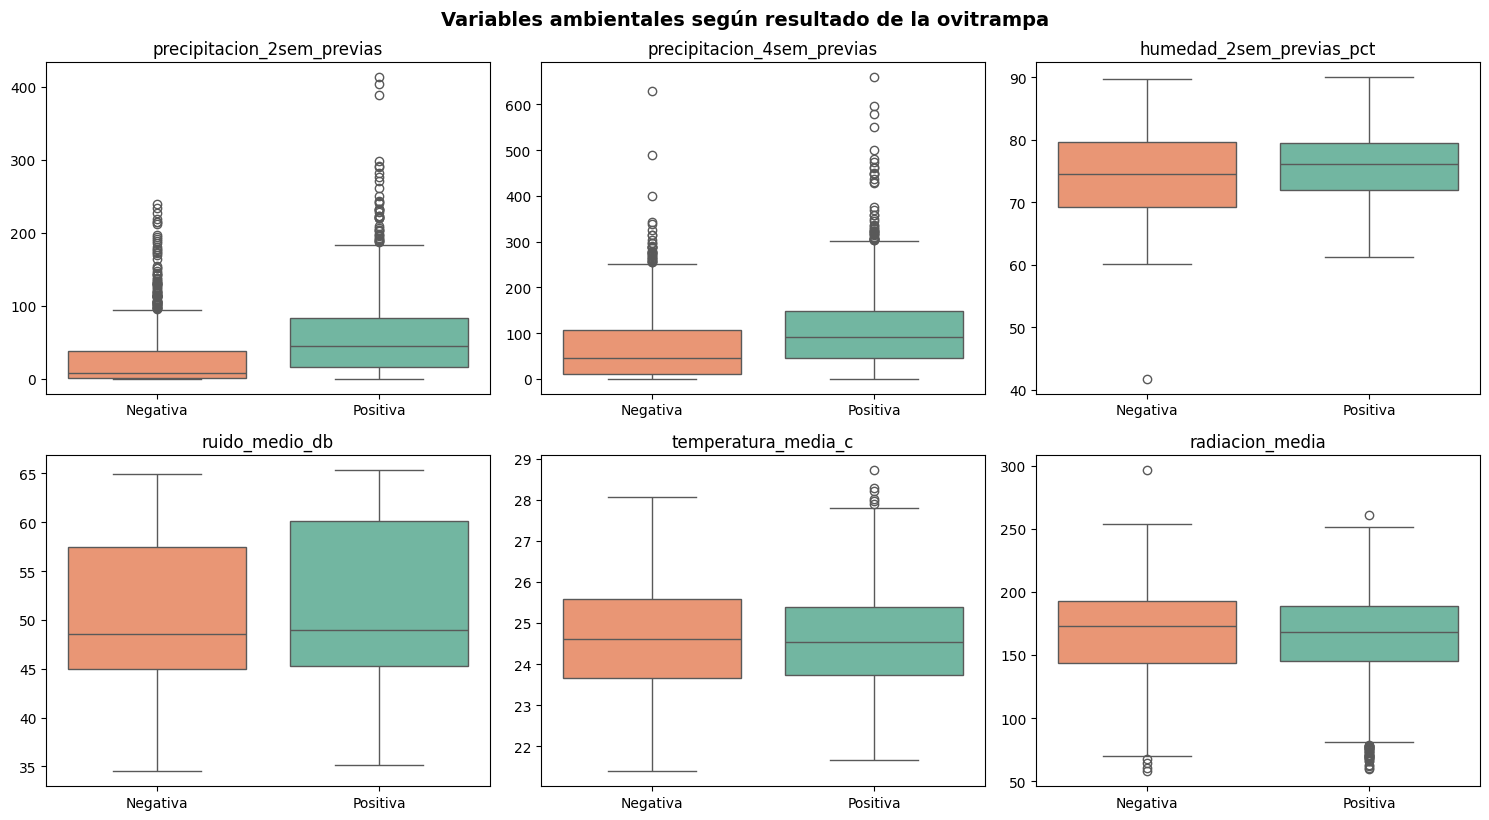

In [ ]:
vars_pos = ["precipitacion_2sem_previas", "precipitacion_4sem_previas", "humedad_2sem_previas_pct",
            "ruido_medio_db", "temperatura_media_c", "radiacion_media"]

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.flatten()

for ax, var in zip(axes, vars_pos):
    sns.boxplot(data=df_aedes_cal, x="ovitrampa", y=var, order=["Negativa", "Positiva"],
                palette="Set2", hue="ovitrampa", legend=False, ax=ax)
    ax.set_title(var)
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.tight_layout()
plt.suptitle("Variables ambientales según resultado de la ovitrampa", y=1.02, fontsize=14, fontweight="bold")
plt.show()

### 5.6 Estacionalidad: huevos por mes

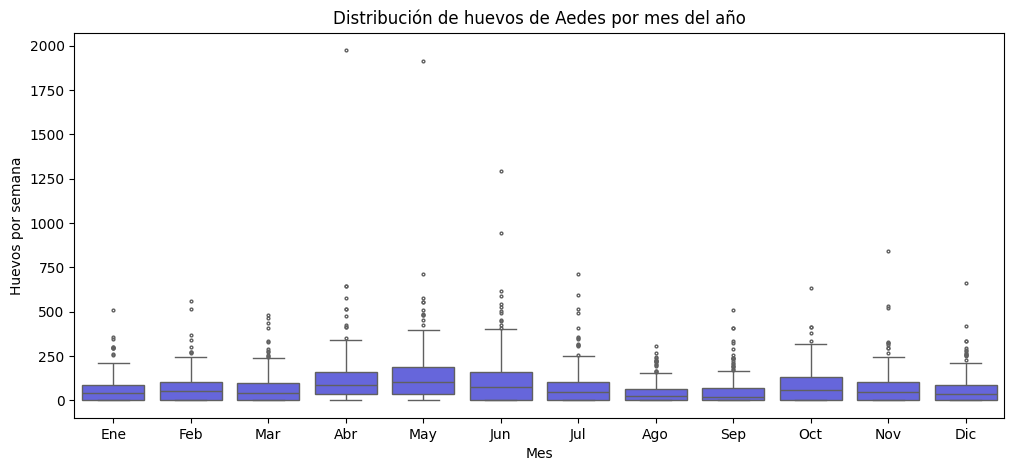

In [ ]:
etiquetas_mes = ["Ene","Feb","Mar","Abr","May","Jun","Jul","Ago","Sep","Oct","Nov","Dic"]

plt.figure(figsize=(12, 5))
sns.boxplot(data=df_aedes, x="mes", y="huevos_aedes", color="#5353EE", fliersize=2)
plt.title("Distribución de huevos de Aedes por mes del año")
plt.xlabel("Mes")
plt.ylabel("Huevos por semana")
plt.xticks(range(12), etiquetas_mes)
plt.show()

## 5.7 Bivariado numérica vs numérica

In [ ]:
vars_num = ["temperatura_media_c", "humedad_media_pct", "radiacion_media", "uv_media",
            "viento_medio", "ruido_medio_db", "pm25_media", "pm10_media",
            "amplitud_termica_c", "precipitacion_semanal", "precipitacion_semana_previa",
            "precipitacion_2sem_previas", "precipitacion_4sem_previas",
            "temperatura_2sem_previas_c", "humedad_2sem_previas_pct", "pm25_2sem_previas"]

corr = pd.DataFrame({
    "Pearson":  df_aedes_cal[vars_num].corrwith(df_aedes_cal["huevos_aedes"], method="pearson"),
    "Spearman": df_aedes_cal[vars_num].corrwith(df_aedes_cal["huevos_aedes"], method="spearman"),
}).round(3).sort_values("Spearman", ascending=False)

corr

,Pearson,Spearman
precipitacion_2sem_previas,0.278,0.472
precipitacion_4sem_previas,0.274,0.403
precipitacion_semana_previa,0.188,0.353
precipitacion_semanal,0.123,0.187
ruido_medio_db,0.188,0.143
humedad_2sem_previas_pct,0.083,0.114
humedad_media_pct,0.044,0.063
temperatura_media_c,0.030,0.012
viento_medio,-0.021,-0.010
temperatura_2sem_previas_c,0.011,-0.018


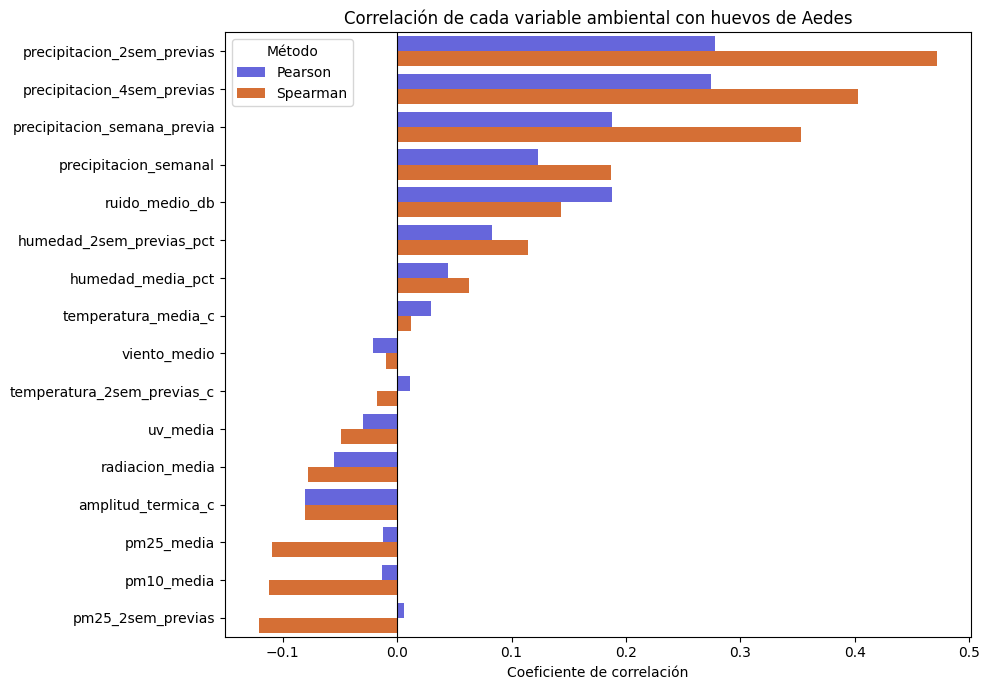

In [ ]:
corr_plot = corr.reset_index().melt(id_vars="index", var_name="Método", value_name="r")

plt.figure(figsize=(10, 7))
sns.barplot(data=corr_plot, y="index", x="r", hue="Método", palette=["#5353EE", "#F0681A"])
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlación de cada variable ambiental con huevos de Aedes")
plt.xlabel("Coeficiente de correlación")
plt.ylabel("")
plt.tight_layout()
plt.show()

Variables con mayor |Spearman|: ['precipitacion_2sem_previas', 'precipitacion_4sem_previas', 'precipitacion_semana_previa']


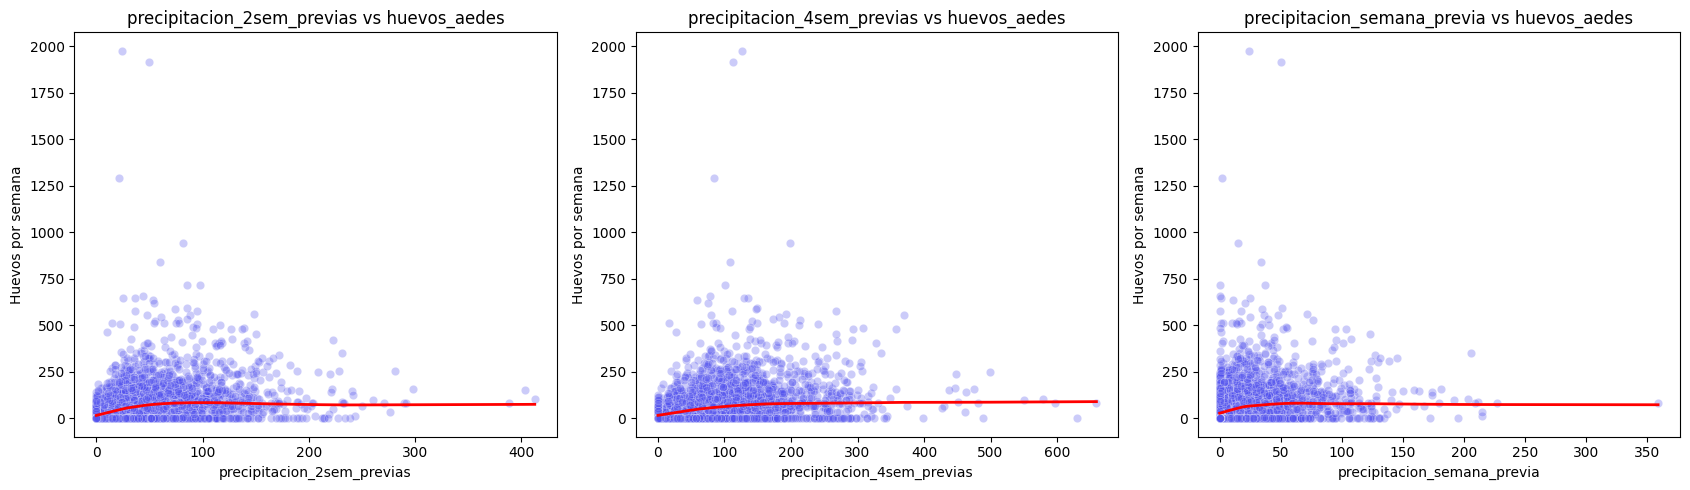

In [ ]:
top = corr["Spearman"].abs().sort_values(ascending=False).index[:3].tolist()
print("Variables con mayor |Spearman|:", top)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, var in zip(axes, top):
    sns.scatterplot(data=df_aedes_cal, x=var, y="huevos_aedes", alpha=0.3, ax=ax, color="#5353EE")
    sns.regplot(data=df_aedes_cal, x=var, y="huevos_aedes", scatter=False, lowess=True,
                line_kws={"color": "red", "linewidth": 2}, ax=ax)
    ax.set_title(f"{var} vs huevos_aedes")
    ax.set_ylabel("Huevos por semana")

plt.tight_layout()
plt.show()

## 5.8 Pruebas estadísticas rápidas

In [ ]:
from scipy import stats

# --- Kruskal-Wallis: huevos_aedes según cada categoría ---
filas = []
for var in ["nodo", "lluvia_2sem", "mes", "año"]:
    grupos = [g["huevos_aedes"].values for _, g in df_aedes_cal.dropna(subset=[var]).groupby(var)]
    H, p = stats.kruskal(*grupos)
    filas.append({"Variable categórica": var, "Nº grupos": len(grupos), "H": round(H, 1), "p-valor": p})

pd.DataFrame(filas)

/tmp/ipykernel_1047/4069469532.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  grupos = [g["huevos_aedes"].values for _, g in df_aedes_cal.dropna(subset=[var]).groupby(var)]


,Variable categórica,Nº grupos,H,p-valor
0,nodo,17,415.6,1.941257e-78
1,lluvia_2sem,4,619.7,5.447574e-134
2,mes,12,188.3,1.968064e-34
3,año,4,8.3,3.989575e-02


In [ ]:
# --- Spearman con p-valor para las variables ambientales ---
filas = []
for var in vars_num:
    sub = df_aedes_cal[[var, "huevos_aedes"]].dropna()
    rho, p = stats.spearmanr(sub[var], sub["huevos_aedes"])
    filas.append({"Variable": var, "n": len(sub), "rho (Spearman)": round(rho, 3), "p-valor": p})

(pd.DataFrame(filas)
   .sort_values("rho (Spearman)", key=abs, ascending=False)
   .reset_index(drop=True))

,Variable,n,rho (Spearman),p-valor
0,precipitacion_2sem_previas,2658,0.472,8.867392e-148
1,precipitacion_4sem_previas,2624,0.403,6.755676e-103
2,precipitacion_semana_previa,2676,0.353,1.474381e-79
3,precipitacion_semanal,2676,0.187,1.389384e-22
4,ruido_medio_db,2676,0.143,9.105453e-14
5,pm25_2sem_previas,2656,-0.121,4.129044e-10
6,humedad_2sem_previas_pct,2654,0.114,4.203904e-09
7,pm10_media,2674,-0.112,7.298265e-09
8,pm25_media,2674,-0.109,1.374797e-08
9,amplitud_termica_c,2672,-0.081,2.935505e-05


### 5.9 Matriz de Correlación Completa

Para visualizar de manera integral cómo se relacionan todas las variables numéricas entre sí, generamos una matriz de correlación utilizando el método de Spearman y la visualizamos con un mapa de calor.

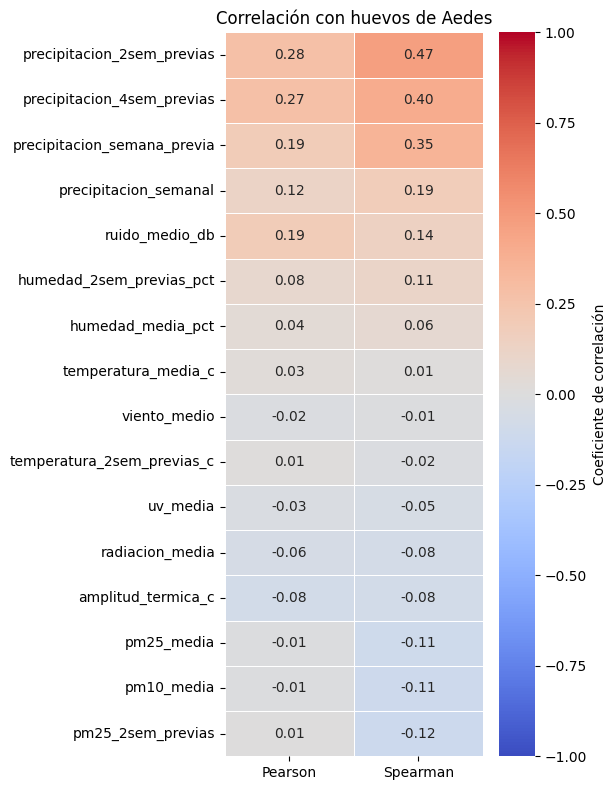

In [ ]:
plt.figure(figsize=(6, 8))
sns.heatmap(corr,
            annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Coeficiente de correlación"})
plt.title("Correlación con huevos de Aedes")
plt.ylabel("")
plt.tight_layout()
plt.show()

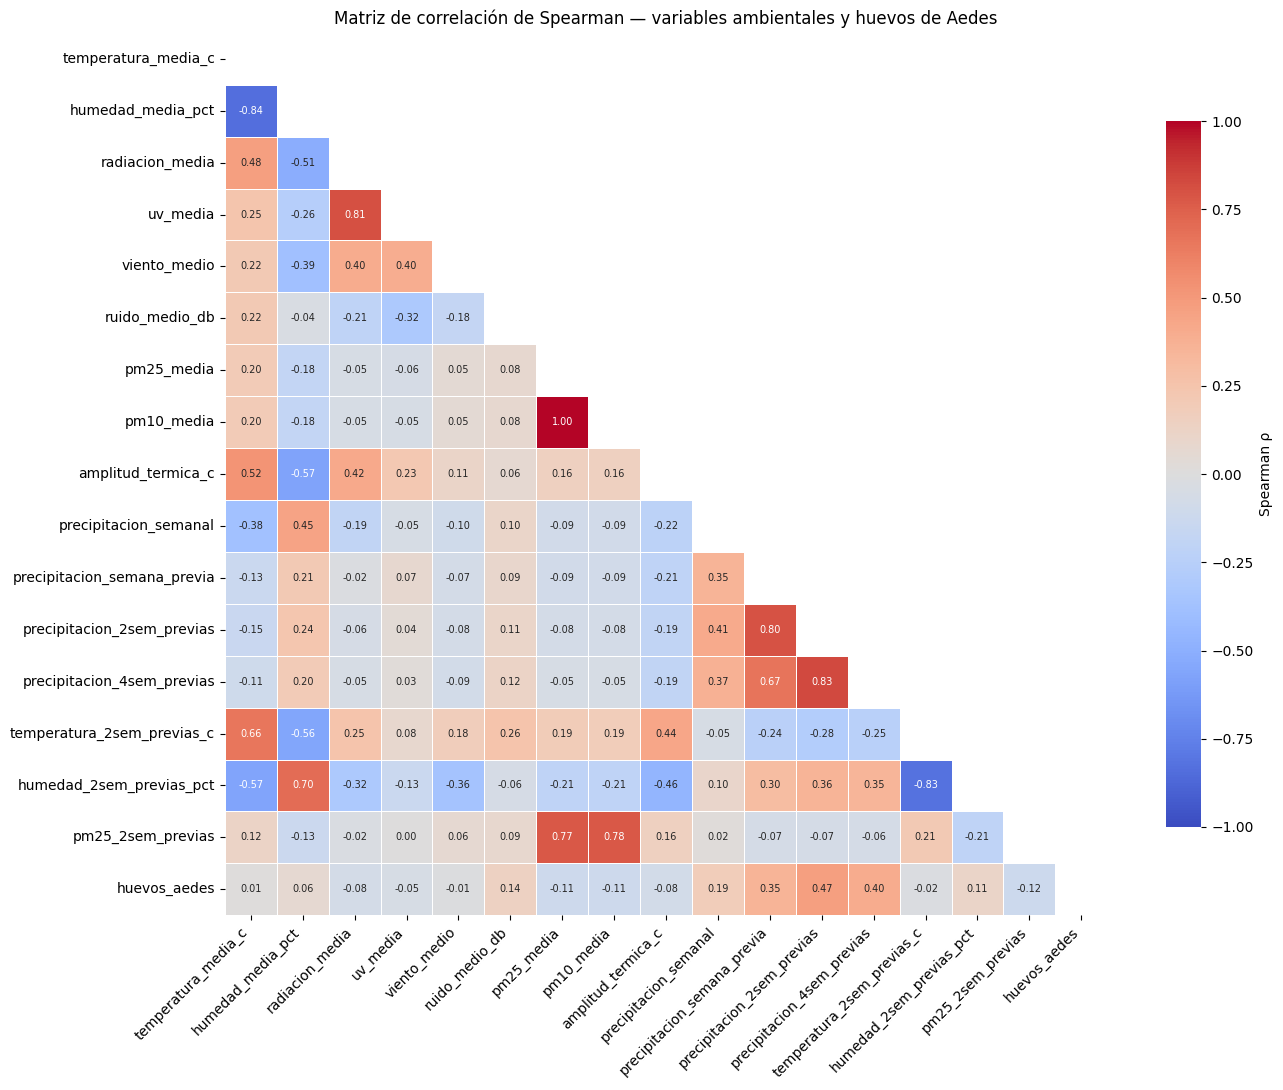

In [ ]:
cols = vars_num + ["huevos_aedes"]
corr_full = df_aedes_cal[cols].corr(method="spearman")

mascara = np.triu(np.ones_like(corr_full, dtype=bool))   # oculta la mitad repetida

plt.figure(figsize=(14, 11))
sns.heatmap(corr_full, mask=mascara,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            cmap="coolwarm", vmin=-1, vmax=1,
            linewidths=0.5, square=True,
            cbar_kws={"shrink": 0.8, "label": "Spearman ρ"})
plt.title("Matriz de correlación de Spearman — variables ambientales y huevos de Aedes")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
variables_corr = vars_num + ["huevos_aedes"]

matriz_corr = df_aedes_cal[variables_corr].corr(method="pearson")
matriz_corr.round(2)

,temperatura_media_c,humedad_media_pct,radiacion_media,uv_media,viento_medio,ruido_medio_db,pm25_media,pm10_media,amplitud_termica_c,precipitacion_semanal,precipitacion_semana_previa,precipitacion_2sem_previas,precipitacion_4sem_previas,temperatura_2sem_previas_c,humedad_2sem_previas_pct,pm25_2sem_previas,huevos_aedes
temperatura_media_c,1.00,-0.84,0.46,0.22,0.23,0.25,0.09,0.08,0.52,-0.34,-0.10,-0.16,-0.14,0.67,-0.58,0.06,0.03
humedad_media_pct,-0.84,1.00,-0.48,-0.22,-0.39,-0.08,-0.05,-0.05,-0.59,0.40,0.18,0.25,0.23,-0.57,0.71,-0.02,0.04
radiacion_media,0.46,-0.48,1.00,0.68,0.40,-0.19,0.02,0.02,0.41,-0.13,0.00,-0.05,-0.06,0.26,-0.31,0.01,-0.06
uv_media,0.22,-0.22,0.68,1.00,0.34,-0.26,0.03,0.03,0.19,-0.03,0.05,0.02,0.01,0.10,-0.14,0.04,-0.03
viento_medio,0.23,-0.39,0.40,0.34,1.00,-0.18,0.09,0.09,0.12,-0.09,-0.07,-0.09,-0.11,0.19,-0.37,0.08,-0.02
ruido_medio_db,0.25,-0.08,-0.19,-0.26,-0.18,1.00,0.03,0.03,0.08,0.09,0.08,0.10,0.12,0.29,-0.11,0.03,0.19
pm25_media,0.09,-0.05,0.02,0.03,0.09,0.03,1.00,1.00,0.02,0.02,-0.00,-0.01,-0.01,0.11,-0.07,0.80,-0.01
pm10_media,0.08,-0.05,0.02,0.03,0.09,0.03,1.00,1.00,0.02,0.02,-0.00,-0.01,-0.01,0.11,-0.07,0.80,-0.01
amplitud_termica_c,0.52,-0.59,0.41,0.19,0.12,0.08,0.02,0.02,1.00,-0.17,-0.19,-0.19,-0.20,0.43,-0.46,0.00,-0.08
precipitacion_semanal,-0.34,0.40,-0.13,-0.03,-0.09,0.09,0.02,0.02,-0.17,1.00,0.19,0.28,0.29,-0.03,0.06,0.06,0.12


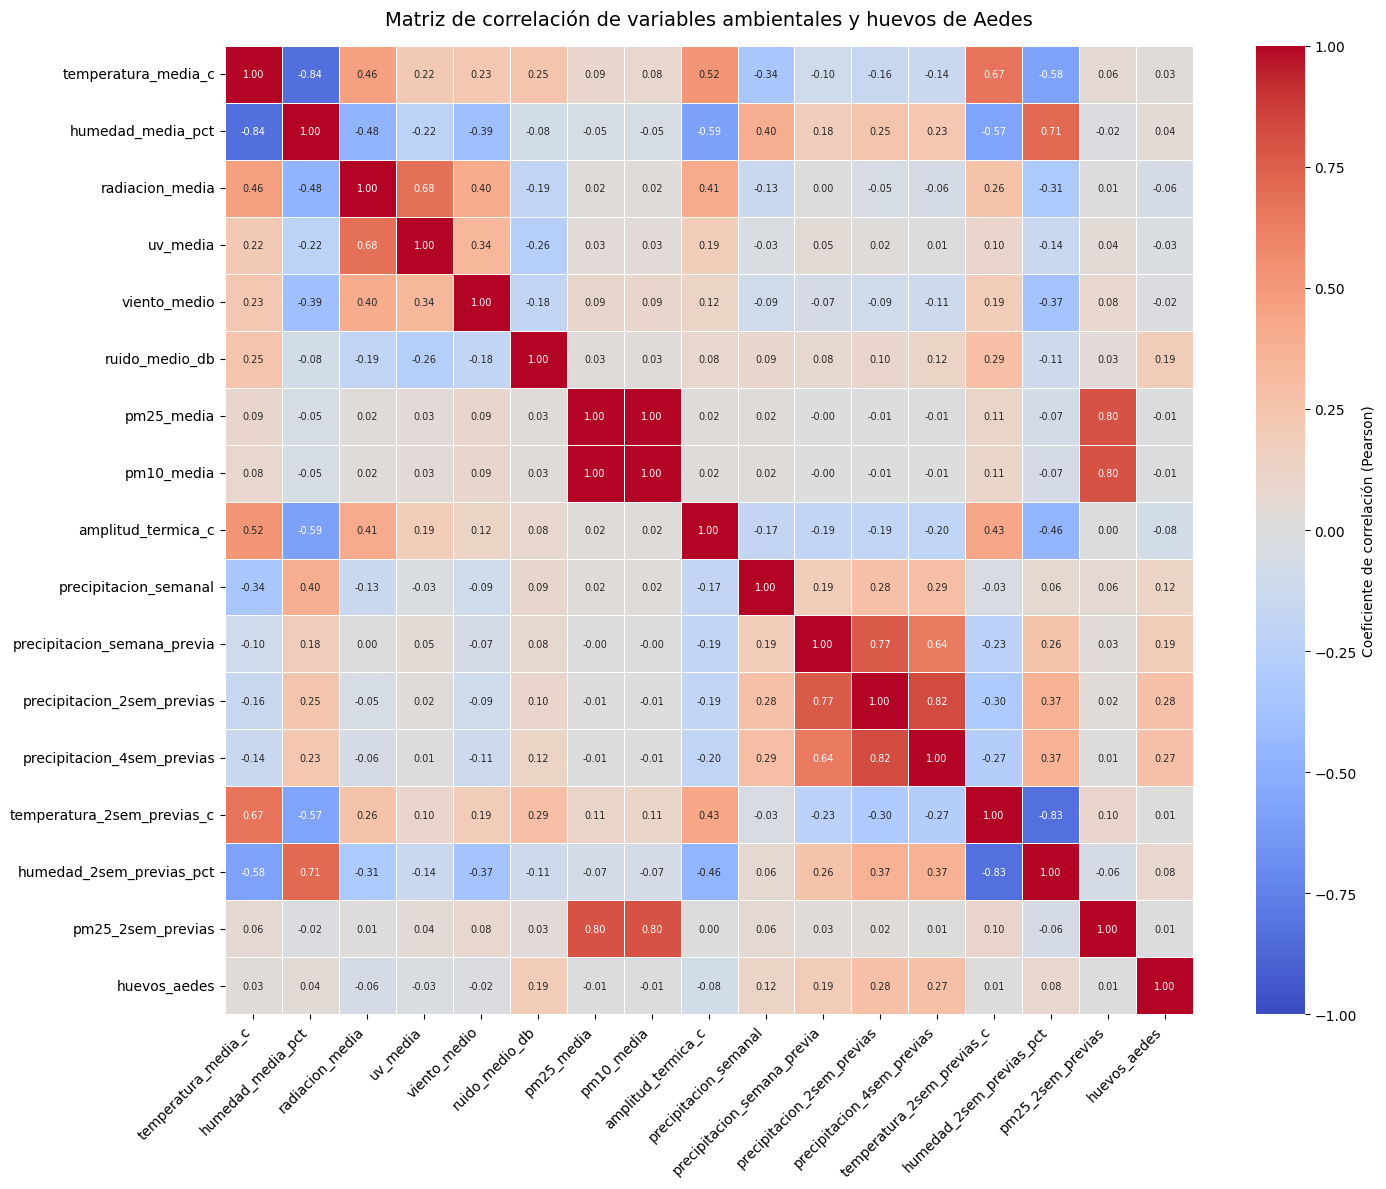

In [ ]:
plt.figure(figsize=(15, 12))
sns.heatmap(
    matriz_corr,
    annot=True,
    annot_kws={"size": 7},      # letra más pequeña porque son 17 variables
    cmap="coolwarm",
    center=0,
    vmin=-1, vmax=1,
    fmt=".2f",
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Coeficiente de correlación (Pearson)"},
)
plt.title("Matriz de correlación de variables ambientales y huevos de Aedes", fontsize=14, pad=15)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()